In [1]:
!pip install -q chromadb sentence-transformers rank-bm25 numpy pandas matplotlib scikit-learn
print("Ready.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 131.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 6.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the 

In [2]:
from google.colab import files
import json
from pathlib import Path

print("Upload your articles JSON file (e.g., TradeRecord_ar-MA.articles.json):")
uploaded = files.upload()

# Load the first JSON file
json_path = list(uploaded.keys())[0]
with open(json_path, "r", encoding="utf-8") as f:
    articles = json.load(f)

print(f"Loaded {len(articles)} articles")

# Show one sample
print("\nSample article keys:", list(articles[0].keys()))
print(f"First article number: {articles[0]['article_number']}")
print(f"First article text preview: {articles[0]['text'][:200]}...")

Upload your articles JSON file (e.g., TradeRecord_ar-MA.articles.json):


Saving 3_TradeRecord_ar-MA.preprocessed.articles.json to 3_TradeRecord_ar-MA.preprocessed.articles.json
Loaded 305 articles

Sample article keys: ['article_number', 'text', 'footnotes', 'context', 'law_name', 'domain']
First article number: 1
First article text preview: -42 استثناء من مقتضيات البند 7 من المادة السابقة، يمكن لكل شخص ذاتي02 ان يصرح بعنوان محل سكناه عندما ال يتوفر على محل لمزاولة نشاطه التجاري او محل لتوطين مقاولته، مالم ينص القانون على خالف ذلك. ولهذه ...


In [3]:
def build_document_text(article):
    """Create searchable text with context prefix."""
    ctx = article.get("context", {})
    parts = []
    if article.get("law_name"):
        parts.append(f"[{article['law_name']}]")
    if ctx.get("section"):
        parts.append(f"[{ctx['section']}]")
    if ctx.get("chapter"):
        parts.append(f"[{ctx['chapter']}]")
    if article.get("article_number"):
        parts.append(f"المادة {article['article_number']}:")
    parts.append(article["text"])
    return " ".join(parts)

doc_texts = []
doc_ids = []
doc_article_numbers = []

for art in articles:
    doc_texts.append(build_document_text(art))
    doc_ids.append(str(len(doc_ids)))
    doc_article_numbers.append(art["article_number"])

print(f"Documents: {len(doc_texts)}")
print(f"Sample:\n{doc_texts[0][:300]}...")

Documents: 305
Sample:
[القانون رقم 15.95 المتعلق بمدونة التجارة كما تم تعديله:] [الباب الثاني: الشهر في السجل التجاري] [الفصل الثاني: التقيدات في السجل التجاري الفرع االول: احكام عامة] المادة 1: -42 استثناء من مقتضيات البند 7 من المادة السابقة، يمكن لكل شخص ذاتي02 ان يصرح بعنوان محل سكناه عندما ال يتوفر على محل لمزاولة ن...


In [5]:
import chromadb
from sentence_transformers import SentenceTransformer
import torch
import time

# Load embedding model (same as your remote embedder)
model = SentenceTransformer("intfloat/multilingual-e5-large")
if torch.cuda.is_available():
    model = model.to("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")

# Embed all documents
print(f"Embedding {len(doc_texts)} documents...")
start = time.time()
doc_embeddings = model.encode(doc_texts, normalize_embeddings=True, show_progress_bar=True)
print(f"Embedded in {time.time() - start:.1f}s")

# Create Chroma collection
client = chromadb.Client()
collection = client.create_collection(
    name="moroccan_legal",
    metadata={"hnsw:space": "cosine"}
)

# Add documents in batches
batch_size = 100
for i in range(0, len(doc_texts), batch_size):
    end = min(i + batch_size, len(doc_texts))
    collection.add(
        ids=doc_ids[i:end],
        documents=doc_texts[i:end],
        embeddings=doc_embeddings[i:end].tolist(),
        metadatas=[{"article_number": n} for n in doc_article_numbers[i:end]]
    )

print(f"ChromaDB collection: {collection.count()} documents")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-large
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using GPU: Tesla T4
Embedding 305 documents...


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Embedded in 10.8s
ChromaDB collection: 305 documents


In [6]:
# Each query has relevant article IDs (from your JSON data)
TEST_QUERIES = [
    {
        "query": "ما هي شروط التسجيل في السجل التجاري؟",
        "relevant_ids": ["1", "42", "2244"]  # from your data
    },
    {
        "query": "كيف يتم تحديد أجل الأداء بين التجار؟",
        "relevant_ids": ["1", "2", "3"]  # article 1-78, 2-78, 3-78
    },
    {
        "query": "ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟",
        "relevant_ids": ["3"]  # article 3-78
    },
    {
        "query": "ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟",
        "relevant_ids": ["42", "2244"]
    },
    {
        "query": "كيف يتم رهن الأصل التجاري؟",
        "relevant_ids": ["106", "107", "108"]
    },
    {
        "query": "ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟",
        "relevant_ids": ["100", "101", "102", "103"]
    },
    {
        "query": "ما هي التزامات التاجر فيما يخص الفوترة والمراسلات؟",
        "relevant_ids": ["42"]  # mentions invoices and correspondence
    },
]

print(f"Test queries: {len(TEST_QUERIES)}")

Test queries: 7


In [13]:
import numpy as np
def dense_search(query, top_k=10):
    """Pure vector similarity search."""
    q_emb = model.encode([query], normalize_embeddings=True)[0]
    results = collection.query(
        query_embeddings=[q_emb.tolist()],
        n_results=top_k,
        include=["metadatas", "distances"]
    )
    ids = results["ids"][0]
    distances = results["distances"][0]
    # Convert cosine distance to similarity
    similarities = [1 - d for d in distances]
    return list(zip(ids, similarities))

def evaluate_strategy(search_fn, queries, top_k=5):
    """Compute Recall@K, MRR, NDCG."""
    recalls = []
    mrrs = []
    ndcgs = []

    for item in queries:
        query = item["query"]
        relevant = set(item["relevant_ids"])

        results = search_fn(query, top_k)  # ← positional, not keyword
        retrieved_ids = [r[0] for r in results]

        # Get article numbers from retrieved IDs
        retrieved_articles = [doc_article_numbers[int(i)] for i in retrieved_ids]

        # Recall@K: proportion of queries where at least one relevant is found
        hit = any(a in relevant for a in retrieved_articles)
        recalls.append(1.0 if hit else 0.0)

        # MRR: 1 / rank of first relevant
        first_rank = None
        for rank, art in enumerate(retrieved_articles, 1):
            if art in relevant:
                first_rank = rank
                break
        mrr = 1.0 / first_rank if first_rank else 0.0
        mrrs.append(mrr)

        # NDCG: DCG / IDCG
        dcg = sum(1.0 / (np.log2(r + 2)) for r, art in enumerate(retrieved_articles) if art in relevant)
        idcg = sum(1.0 / (np.log2(r + 2)) for r in range(min(len(relevant), top_k)))
        ndcg = dcg / idcg if idcg > 0 else 0.0
        ndcgs.append(ndcg)

        # Print per-query
        print(f"Query: {query}")
        print(f"  Retrieved: {retrieved_articles[:5]}")
        print(f"  Relevant: {relevant}")
        print(f"  Hit: {hit}, MRR: {mrr:.3f}, NDCG: {ndcg:.3f}")
        print()

    return {
        "Recall@K": np.mean(recalls),
        "MRR": np.mean(mrrs),
        "NDCG@K": np.mean(ndcgs),
    }

print("=" * 60)
print("DENSE RETRIEVAL")
print("=" * 60)
dense_metrics = evaluate_strategy(dense_search, TEST_QUERIES, top_k=5)
print(f"\nDense Metrics: {dense_metrics}")

DENSE RETRIEVAL
Query: ما هي شروط التسجيل في السجل التجاري؟
  Retrieved: ['42', '1', '154', '2244', '7']
  Relevant: {'2244', '1', '42'}
  Hit: True, MRR: 1.000, NDCG: 0.967

Query: كيف يتم تحديد أجل الأداء بين التجار؟
  Retrieved: ['2', '116', '1', '143', '144']
  Relevant: {'1', '2', '3'}
  Hit: True, MRR: 1.000, NDCG: 0.704

Query: ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟
  Retrieved: ['3', '2', '738', '3', '682']
  Relevant: {'3'}
  Hit: True, MRR: 1.000, NDCG: 1.431

Query: ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟
  Retrieved: ['4', '104', '2244', '42', '7']
  Relevant: {'2244', '42'}
  Hit: True, MRR: 0.333, NDCG: 0.571

Query: كيف يتم رهن الأصل التجاري؟
  Retrieved: ['107', '108', '106', '109', '7']
  Relevant: {'106', '108', '107'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟
  Retrieved: ['101', '103', '100', '102', '123']
  Relevant: {'102', '100', '103', '101'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Que

In [14]:
from rank_bm25 import BM25Okapi
import re

def tokenize(text):
    """Simple Arabic tokenization."""
    return text.split()

# Build BM25 index
tokenized_docs = [tokenize(doc) for doc in doc_texts]
bm25 = BM25Okapi(tokenized_docs)

def bm25_search(query, top_k=10):
    tokenized_query = tokenize(query)
    scores = bm25.get_scores(tokenized_query)
    # Get top-k indices
    top_indices = np.argsort(scores)[::-1][:top_k]
    results = []
    for idx in top_indices:
        results.append((str(idx), float(scores[idx])))
    return results

print("=" * 60)
print("BM25 RETRIEVAL")
print("=" * 60)
bm25_metrics = evaluate_strategy(bm25_search, TEST_QUERIES, top_k=5)
print(f"\nBM25 Metrics: {bm25_metrics}")

BM25 RETRIEVAL
Query: ما هي شروط التسجيل في السجل التجاري؟
  Retrieved: ['42', '2244', '1', '3', '7']
  Relevant: {'2244', '1', '42'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: كيف يتم تحديد أجل الأداء بين التجار؟
  Retrieved: ['721', '730', '667', '724', '790']
  Relevant: {'1', '2', '3'}
  Hit: False, MRR: 0.000, NDCG: 0.000

Query: ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟
  Retrieved: ['3', '588', '631', '782', '630']
  Relevant: {'3'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟
  Retrieved: ['8', '2244', '42', '2', '750']
  Relevant: {'2244', '42'}
  Hit: True, MRR: 0.500, NDCG: 0.693

Query: كيف يتم رهن الأصل التجاري؟
  Retrieved: ['12', '106', '1', '107', '392']
  Relevant: {'106', '108', '107'}
  Hit: True, MRR: 0.500, NDCG: 0.498

Query: ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟
  Retrieved: ['101', '103', '102', '702', '737']
  Relevant: {'102', '100', '103', '101'}
  Hit: True, MRR: 1.000, NDCG: 0.832

In [15]:
def hybrid_search(query, top_k=10, alpha=0.7):
    """alpha: weight for dense (1-alpha for BM25)."""
    # Dense
    q_emb = model.encode([query], normalize_embeddings=True)[0]
    dense_results = collection.query(
        query_embeddings=[q_emb.tolist()],
        n_results=len(doc_texts),  # get all
        include=["distances"]
    )
    dense_scores = {doc_ids[i]: 1 - dense_results["distances"][0][i]
                    for i in range(len(doc_ids))}

    # BM25
    tokenized_query = tokenize(query)
    bm25_scores = bm25.get_scores(tokenized_query)

    # Normalize BM25 scores to [0, 1]
    bm25_min = bm25_scores.min()
    bm25_max = bm25_scores.max()
    if bm25_max > bm25_min:
        bm25_normalized = (bm25_scores - bm25_min) / (bm25_max - bm25_min)
    else:
        bm25_normalized = np.zeros_like(bm25_scores)

    # Combine
    combined = {}
    for i, doc_id in enumerate(doc_ids):
        dense_score = dense_scores.get(doc_id, 0)
        bm25_score = float(bm25_normalized[i])
        combined[doc_id] = alpha * dense_score + (1 - alpha) * bm25_score

    # Sort and return top-k
    sorted_docs = sorted(combined.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return sorted_docs

print("=" * 60)
print("HYBRID RETRIEVAL (alpha=0.7)")
print("=" * 60)
hybrid_metrics = evaluate_strategy(
    lambda q, k: hybrid_search(q, k),  # ← removed top_k=, pass positionally
    TEST_QUERIES, top_k=5
)
print(f"\nHybrid Metrics: {hybrid_metrics}")

HYBRID RETRIEVAL (alpha=0.7)
Query: ما هي شروط التسجيل في السجل التجاري؟
  Retrieved: ['42', '2244', '1', '3', '7']
  Relevant: {'2244', '1', '42'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: كيف يتم تحديد أجل الأداء بين التجار؟
  Retrieved: ['721', '730', '667', '724', '2']
  Relevant: {'1', '2', '3'}
  Hit: True, MRR: 0.200, NDCG: 0.182

Query: ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟
  Retrieved: ['3', '588', '631', '630', '2']
  Relevant: {'3'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟
  Retrieved: ['8', '2244', '42', '2', '4']
  Relevant: {'2244', '42'}
  Hit: True, MRR: 0.500, NDCG: 0.693

Query: كيف يتم رهن الأصل التجاري؟
  Retrieved: ['12', '106', '107', '1', '392']
  Relevant: {'106', '108', '107'}
  Hit: True, MRR: 0.500, NDCG: 0.531

Query: ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟
  Retrieved: ['101', '103', '102', '100', '120']
  Relevant: {'102', '100', '103', '101'}
  Hit: True, MRR: 1.000, NDCG

In [16]:
# ============================================
# CELL 9: Test Different Alpha Values
# ============================================

print("=" * 60)
print("ALPHA TUNING (Dense weight)")
print("=" * 60)

alpha_results = {}
for alpha in [0.3, 0.5, 0.7, 0.9]:
    metrics = evaluate_strategy(
        lambda q, k, a=alpha: hybrid_search(q, k, alpha=a),
        TEST_QUERIES, top_k=5
    )
    alpha_results[alpha] = metrics
    print(f"\nalpha={alpha}: Recall={metrics['Recall@K']:.2f}, MRR={metrics['MRR']:.3f}, NDCG={metrics['NDCG@K']:.3f}")

# Best alpha
best_alpha = max(alpha_results, key=lambda a: alpha_results[a]["MRR"])
print(f"\nBest alpha: {best_alpha} (MRR={alpha_results[best_alpha]['MRR']:.3f})")
print(f"Recall@K: {alpha_results[best_alpha]['Recall@K']:.2f}")
print(f"NDCG@K: {alpha_results[best_alpha]['NDCG@K']:.3f}")

ALPHA TUNING (Dense weight)
Query: ما هي شروط التسجيل في السجل التجاري؟
  Retrieved: ['42', '2244', '1', '3', '7']
  Relevant: {'2244', '1', '42'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: كيف يتم تحديد أجل الأداء بين التجار؟
  Retrieved: ['721', '730', '667', '724', '790']
  Relevant: {'1', '2', '3'}
  Hit: False, MRR: 0.000, NDCG: 0.000

Query: ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟
  Retrieved: ['3', '588', '631', '630', '782']
  Relevant: {'3'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟
  Retrieved: ['8', '2244', '42', '2', '750']
  Relevant: {'2244', '42'}
  Hit: True, MRR: 0.500, NDCG: 0.693

Query: كيف يتم رهن الأصل التجاري؟
  Retrieved: ['12', '106', '107', '1', '392']
  Relevant: {'106', '108', '107'}
  Hit: True, MRR: 0.500, NDCG: 0.531

Query: ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟
  Retrieved: ['101', '103', '102', '702', '120']
  Relevant: {'102', '100', '103', '101'}
  Hit: True, MRR: 1.000

RECIPROCAL RANK FUSION
Query: ما هي شروط التسجيل في السجل التجاري؟
  Retrieved: ['42', '1', '2244', '7', '3']
  Relevant: {'2244', '1', '42'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: كيف يتم تحديد أجل الأداء بين التجار؟
  Retrieved: ['2', '1', '147', '3', '713']
  Relevant: {'1', '2', '3'}
  Hit: True, MRR: 1.000, NDCG: 0.967

Query: ما هو التعويض عن التأخير في أداء المبالغ المستحقة؟
  Retrieved: ['3', '2', '631', '738', '588']
  Relevant: {'3'}
  Hit: True, MRR: 1.000, NDCG: 1.000

Query: ما هي البيانات التي يجب على الشركات التجارية التصريح بها؟
  Retrieved: ['2244', '4', '42', '720', '2']
  Relevant: {'2244', '42'}
  Hit: True, MRR: 1.000, NDCG: 0.920

Query: كيف يتم رهن الأصل التجاري؟
  Retrieved: ['107', '106', '12', '108', '1']
  Relevant: {'106', '108', '107'}
  Hit: True, MRR: 1.000, NDCG: 0.967

Query: ما هي إجراءات دعوى الفسخ في بيع الأصل التجاري؟
  Retrieved: ['101', '103', '102', '100', '702']
  Relevant: {'102', '100', '103', '101'}
  Hit: True, MRR: 1.000, NDCG: 1.000


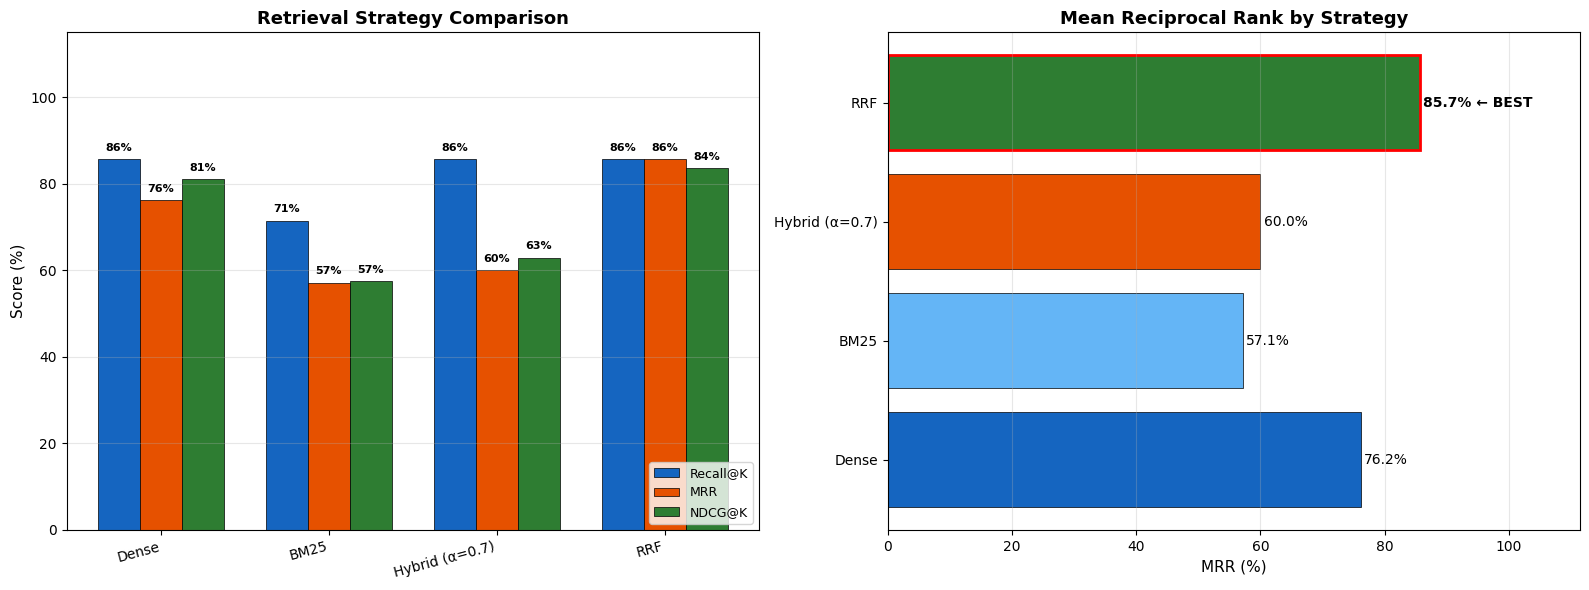

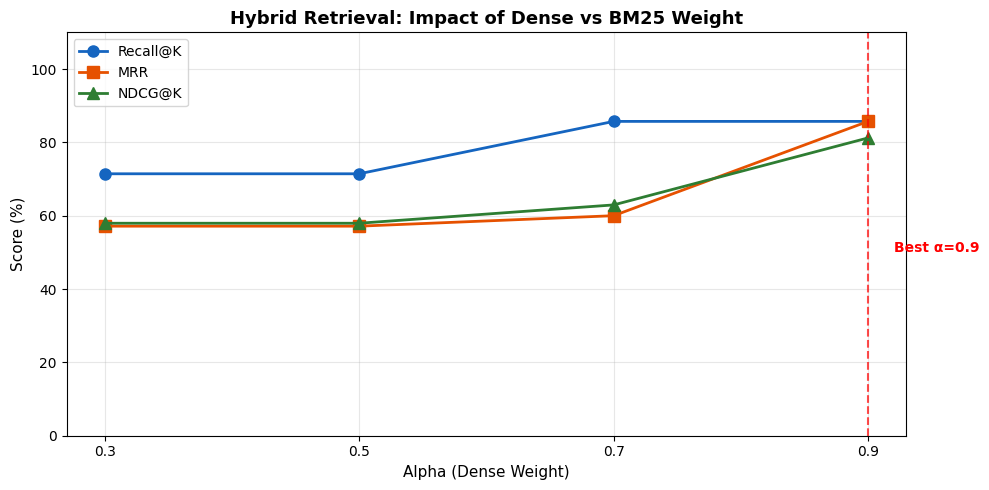

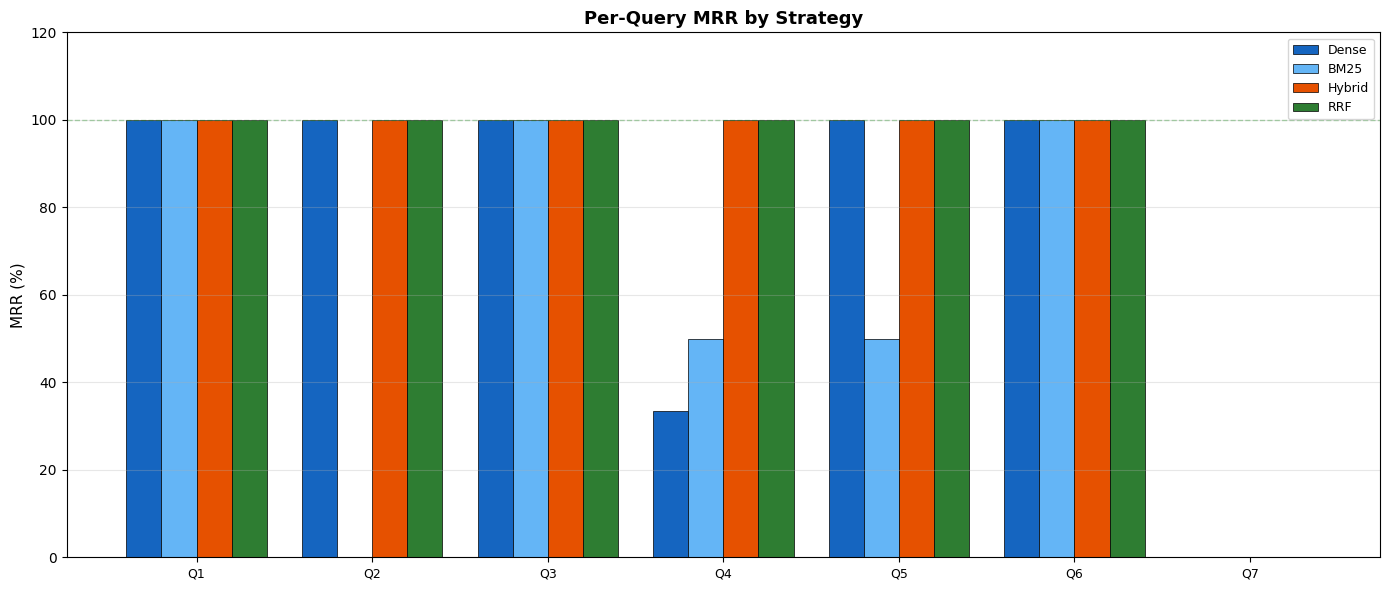

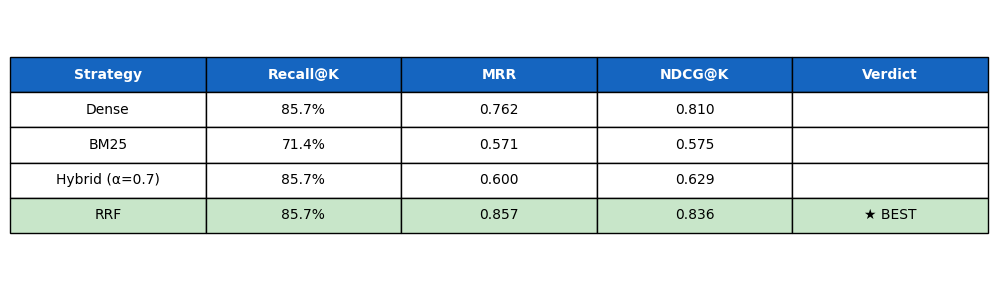


FINAL RECOMMENDATION

Recommended strategy: RRF

Performance:
  Recall@K: 85.7%  (proportion of queries with at least one relevant result)
  MRR:      0.857     (mean reciprocal rank of first relevant result)
  NDCG@K:   0.836    (quality-weighted ranking score)

Why this strategy:

  - Reciprocal Rank Fusion gives the best results
  - No weight tuning needed - simpler to implement and maintain
  - Implement RRF in src/retrieval/search.py

Next step:
  Implement this strategy in src/retrieval/search.py
  and wire it into the POST /search API endpoint.



In [17]:
# ============================================
# CELL 10: Reciprocal Rank Fusion (RRF)
# ============================================

def rrf_search(query, top_k=10, k_rrf=60):
    """Reciprocal Rank Fusion - no weights needed."""
    # Get dense ranks
    q_emb = model.encode([query], normalize_embeddings=True)[0]
    dense_results = collection.query(
        query_embeddings=[q_emb.tolist()],
        n_results=len(doc_texts),
    )
    dense_ranks = {doc_id: rank + 1 for rank, doc_id in enumerate(dense_results["ids"][0])}

    # Get BM25 ranks
    tokenized_query = tokenize(query)
    bm25_scores = bm25.get_scores(tokenized_query)
    bm25_indices = np.argsort(bm25_scores)[::-1]
    bm25_ranks = {str(idx): rank + 1 for rank, idx in enumerate(bm25_indices)}

    # RRF formula: score = sum(1 / (k + rank))
    rrf_scores = {}
    for doc_id in doc_ids:
        dense_rank = dense_ranks.get(doc_id, len(doc_ids))
        bm25_rank = bm25_ranks.get(doc_id, len(doc_ids))
        rrf_scores[doc_id] = 1.0 / (k_rrf + dense_rank) + 1.0 / (k_rrf + bm25_rank)

    sorted_docs = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return sorted_docs


print("=" * 60)
print("RECIPROCAL RANK FUSION")
print("=" * 60)
rrf_metrics = evaluate_strategy(
    lambda q, k: rrf_search(q, k),
    TEST_QUERIES, top_k=5
)
print(f"\nRRF Metrics: {rrf_metrics}")


# ============================================
# VISUALIZATIONS
# ============================================

import matplotlib.pyplot as plt
import pandas as pd

# ---- FIGURE 1: All strategies comparison ----
all_metrics = {
    "Dense": dense_metrics,
    "BM25": bm25_metrics,
    "Hybrid (α=0.7)": hybrid_metrics,
    "RRF": rrf_metrics,
}

df = pd.DataFrame(all_metrics).T

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1a: Grouped bar chart - all metrics per strategy
ax = axes[0]
x = range(len(df))
width = 0.25
metrics_list = ["Recall@K", "MRR", "NDCG@K"]
colors = ["#1565C0", "#E65100", "#2E7D32"]

for i, metric in enumerate(metrics_list):
    bars = ax.bar([p + i*width for p in x], df[metric] * 100, width,
                  label=metric, color=colors[i], edgecolor='black', linewidth=0.5)
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 1.5, f'{height:.0f}%',
                ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks([p + width for p in x])
ax.set_xticklabels(df.index, rotation=15, ha='right', fontsize=10)
ax.set_ylabel("Score (%)", fontsize=11)
ax.set_title("Retrieval Strategy Comparison", fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_ylim(0, 115)
ax.grid(axis='y', alpha=0.3)

# 1b: MRR-focused comparison (best metric for retrieval quality)
ax = axes[1]
strategies = list(df.index)
mrr_values = df["MRR"].values * 100
bar_colors = ["#1565C0", "#64B5F6", "#E65100", "#2E7D32"]
bars = ax.barh(strategies, mrr_values, color=bar_colors, edgecolor='black', linewidth=0.5)

# Highlight best
best_idx = df["MRR"].idxmax()
best_pos = list(df.index).index(best_idx)
bars[best_pos].set_edgecolor('#FF0000')
bars[best_pos].set_linewidth(2)

for i, (bar, val) in enumerate(zip(bars, mrr_values)):
    label = f"{val:.1f}%"
    if i == best_pos:
        label += " ← BEST"
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            label, va='center', fontsize=10,
            fontweight='bold' if i == best_pos else 'normal')

ax.set_xlabel("MRR (%)", fontsize=11)
ax.set_title("Mean Reciprocal Rank by Strategy", fontsize=13, fontweight='bold')
ax.set_xlim(0, max(mrr_values) * 1.3)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


# ---- FIGURE 2: Alpha tuning ----
fig, ax = plt.subplots(figsize=(10, 5))

alphas = list(alpha_results.keys())
recalls = [alpha_results[a]["Recall@K"] * 100 for a in alphas]
mrrs = [alpha_results[a]["MRR"] * 100 for a in alphas]
ndcgs = [alpha_results[a]["NDCG@K"] * 100 for a in alphas]

ax.plot(alphas, recalls, 'o-', color='#1565C0', linewidth=2, markersize=8, label='Recall@K')
ax.plot(alphas, mrrs, 's-', color='#E65100', linewidth=2, markersize=8, label='MRR')
ax.plot(alphas, ndcgs, '^-', color='#2E7D32', linewidth=2, markersize=8, label='NDCG@K')

# Highlight best alpha
best_alpha = max(alpha_results, key=lambda a: alpha_results[a]["MRR"])
ax.axvline(x=best_alpha, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(best_alpha + 0.02, 50, f'Best α={best_alpha}', color='red', fontsize=10, fontweight='bold')

ax.set_xlabel("Alpha (Dense Weight)", fontsize=11)
ax.set_ylabel("Score (%)", fontsize=11)
ax.set_title("Hybrid Retrieval: Impact of Dense vs BM25 Weight", fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_ylim(0, 110)
ax.set_xticks(alphas)

plt.tight_layout()
plt.show()


# ---- FIGURE 3: Per-query MRR comparison ----
fig, ax = plt.subplots(figsize=(14, 6))

query_labels = [f"Q{i+1}" for i in range(len(TEST_QUERIES))]
x = range(len(TEST_QUERIES))
width = 0.2

strategies_to_plot = {
    "Dense": lambda q, k: dense_search(q, k),
    "BM25": lambda q, k: bm25_search(q, k),
    "Hybrid": lambda q, k: hybrid_search(q, k, alpha=best_alpha),
    "RRF": lambda q, k: rrf_search(q, k),
}

colors = ["#1565C0", "#64B5F6", "#E65100", "#2E7D32"]

for i, (name, search_fn) in enumerate(strategies_to_plot.items()):
    per_query_mrr = []
    for item in TEST_QUERIES:
        results = search_fn(item["query"], 5)
        retrieved_ids = [r[0] for r in results]
        retrieved_articles = [doc_article_numbers[int(r)] for r in retrieved_ids]
        relevant = set(item["relevant_ids"])
        first_rank = None
        for rank, art in enumerate(retrieved_articles, 1):
            if art in relevant:
                first_rank = rank
                break
        mrr = 1.0 / first_rank if first_rank else 0.0
        per_query_mrr.append(mrr * 100)

    ax.bar([p + i*width for p in x], per_query_mrr, width,
           label=name, color=colors[i], edgecolor='black', linewidth=0.5)

ax.set_xticks([p + 1.5*width for p in x])
ax.set_xticklabels(query_labels, fontsize=9)
ax.set_ylabel("MRR (%)", fontsize=11)
ax.set_title("Per-Query MRR by Strategy", fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.set_ylim(0, 120)
ax.axhline(y=100, color='green', linestyle='--', alpha=0.3, linewidth=1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


# ---- FIGURE 4: Summary table ----
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

table_data = []
table_data.append(["Strategy", "Recall@K", "MRR", "NDCG@K", "Verdict"])
for name in df.index:
    row = [
        name,
        f"{df.loc[name, 'Recall@K']:.1%}",
        f"{df.loc[name, 'MRR']:.3f}",
        f"{df.loc[name, 'NDCG@K']:.3f}",
        "★ BEST" if name == df["MRR"].idxmax() else ""
    ]
    table_data.append(row)

table = ax.table(cellText=table_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

# Style header
for i in range(len(table_data[0])):
    table[0, i].set_facecolor('#1565C0')
    table[0, i].set_text_props(color='white', fontweight='bold')

# Highlight best row
best_row = list(df.index).index(df["MRR"].idxmax()) + 1
for i in range(len(table_data[0])):
    table[best_row, i].set_facecolor('#C8E6C9')

plt.tight_layout()
plt.show()


# ============================================
# RECOMMENDATION
# ============================================
print("\n" + "=" * 60)
print("FINAL RECOMMENDATION")
print("=" * 60)

best_strategy = df["MRR"].idxmax()
best_recall = df.loc[best_strategy, "Recall@K"]
best_mrr = df.loc[best_strategy, "MRR"]
best_ndcg = df.loc[best_strategy, "NDCG@K"]

print(f"""
Recommended strategy: {best_strategy}

Performance:
  Recall@K: {best_recall:.1%}  (proportion of queries with at least one relevant result)
  MRR:      {best_mrr:.3f}     (mean reciprocal rank of first relevant result)
  NDCG@K:   {best_ndcg:.3f}    (quality-weighted ranking score)

Why this strategy:
""")

if best_strategy == "Dense":
    print("  - Pure vector search is sufficient for this dataset")
    print("  - BM25 does not improve results, so keep the pipeline simple")
    print("  - No need for hybrid or reranking")
elif "Hybrid" in best_strategy:
    print(f"  - Hybrid retrieval with alpha={best_alpha} outperforms pure dense or BM25")
    print("  - Both semantic and lexical signals matter for legal text")
    print("  - Implement weighted fusion in src/retrieval/search.py")
elif best_strategy == "RRF":
    print("  - Reciprocal Rank Fusion gives the best results")
    print("  - No weight tuning needed - simpler to implement and maintain")
    print("  - Implement RRF in src/retrieval/search.py")
else:
    print("  - BM25 alone works best for keyword-heavy legal queries")

print("""
Next step:
  Implement this strategy in src/retrieval/search.py
  and wire it into the POST /search API endpoint.
""")
print("=" * 60)